# Detecting Heart Abnormalities Using ECG with CART

**Goal:** reproduce the reference paper's model comparison as closely as the available details allow, then extend it with Random Forest.

This notebook uses the UCI Arrhythmia dataset from a `arrhythmia`. It is a coursework experiment, not a medical diagnostic tool.

## 1. Imports and dataset

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
os.makedirs("results", exist_ok=True)

DATA_PATH = "/content/Data_set/arrhythmia.data"

if DATA_PATH is None:
    raise FileNotFoundError(
        "Upload arrhythmia.data to Colab, or place it beside this notebook."
    )

df = pd.read_csv(DATA_PATH, header=None, na_values="?")
df = df.apply(pd.to_numeric, errors="coerce")

print("Loaded:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Loaded: /content/Data_set/arrhythmia.data
Dataset shape: (452, 280)


,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
0,75,0,190,80,91,193,371,174,121,-16,...,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8
1,56,1,165,64,81,174,401,149,39,25,...,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6
2,54,0,172,95,138,163,386,185,102,96,...,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10
3,55,0,175,94,100,202,380,179,143,28,...,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1
4,75,0,190,80,88,181,360,177,103,-16,...,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7


## 2. Inspect and prepare the data

Missing values: 408
Duplicate rows: 0


,Missing (%)
13,83.185841
11,4.867257
10,1.769912
14,0.221239
12,0.221239


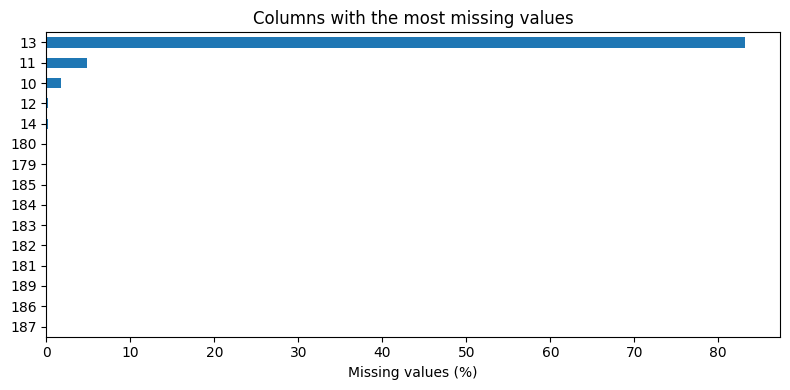

Original class counts:


,Records
279,
1,245
2,44
3,15
4,15
5,13
6,25
7,3
8,2
9,9


In [14]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
display(missing_pct[missing_pct > 0].head(15).rename("Missing (%)").to_frame())

plt.figure(figsize=(8, 4))
missing_pct.head(15).sort_values().plot(kind="barh")
plt.xlabel("Missing values (%)")
plt.title("Columns with the most missing values")
plt.tight_layout()
plt.show()

print("Original class counts:")
display(df.iloc[:, -1].value_counts(dropna=False).sort_index().rename("Records").to_frame())

The reference paper describes 452 records, 279 input features and 16 possible class labels. Feature 14 is removed because the paper reports that it is largely missing. Some class labels do not occur in this dataset, and several present classes have very few records. Median imputation is fitted inside each model pipeline to avoid using test-set information.

The paper reports approximately 80% CART accuracy and an `rpart` complexity parameter around 0.027. R's `cp` and scikit-learn's `ccp_alpha` are not directly interchangeable. Since the paper does not fully specify a matching train/test split and all library settings, this is a **reproduction attempt**, not an exact replication.

In [15]:
df = df.loc[df.iloc[:, -1].notna()].copy()

X = df.iloc[:, :-1].copy()
y = df.iloc[:, -1].astype(int)

if 13 in X.columns:
    X = X.drop(columns=13)

X = X.dropna(axis=1, how="all")
class_labels = sorted(y.unique())
class_counts = y.value_counts().sort_index()

print("Records:", len(X))
print("Features after removing feature 14 and empty columns:", X.shape[1])
print("Available classes:", class_labels)
display(class_counts.rename("Records").to_frame())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Records: 452
Features after removing feature 14 and empty columns: 278
Available classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(14), np.int64(15), np.int64(16)]


,Records
279,
1,245
2,44
3,15
4,15
5,13
6,25
7,3
8,2
9,9


Training records: 316
Testing records: 136


# Part A — Reproduce the reference models

The reference study's main model is CART and it also evaluates SVM and Naive Bayes. All models below use the same fixed training/test split. Any differences from the paper's result may come from the split, preprocessing, software implementation, and handling of rare classes.

## A1. CART

In [16]:
cart_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold(threshold=0.0)),
    ("model", DecisionTreeClassifier(
        criterion="gini",
        random_state=RANDOM_STATE
    ))
])

# Fixed alpha candidates avoid deriving the search grid from all training rows.
alpha_values = [0.0, 0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.027, 0.04, 0.06]
cart_search = GridSearchCV(
    cart_model,
    param_grid={"model__ccp_alpha": alpha_values},
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="accuracy",
    n_jobs=-1
)
cart_search.fit(X_train, y_train)
cart_model = cart_search.best_estimator_
pred_cart = cart_model.predict(X_test)

print("Selected CART ccp_alpha:", cart_search.best_params_["model__ccp_alpha"])
print("CART test accuracy:", f"{accuracy_score(y_test, pred_cart):.2%}")
print(classification_report(y_test, pred_cart, labels=class_labels, zero_division=0))

Selected CART ccp_alpha: 0.02
CART test accuracy: 63.24%
              precision    recall  f1-score   support

           1       0.68      0.81      0.74        74
           2       0.64      0.54      0.58        13
           3       0.00      0.00      0.00         4
           4       0.20      0.50      0.29         4
           5       0.00      0.00      0.00         4
           6       0.70      0.88      0.78         8
           7       0.00      0.00      0.00         1
           8       0.00      0.00      0.00         1
           9       0.00      0.00      0.00         3
          10       0.71      0.67      0.69        15
          14       0.00      0.00      0.00         1
          15       0.00      0.00      0.00         1
          16       0.00      0.00      0.00         7

    accuracy                           0.63       136
   macro avg       0.23      0.26      0.24       136
weighted avg       0.56      0.63      0.59       136



<Figure size 1000x800 with 0 Axes>

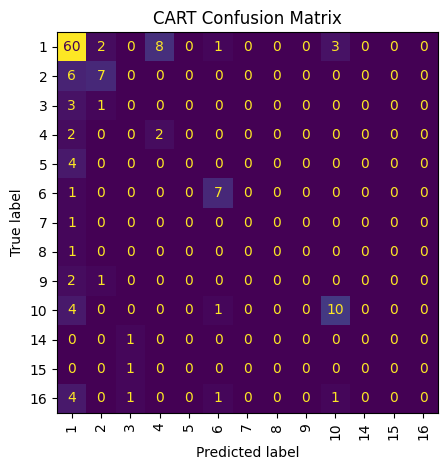

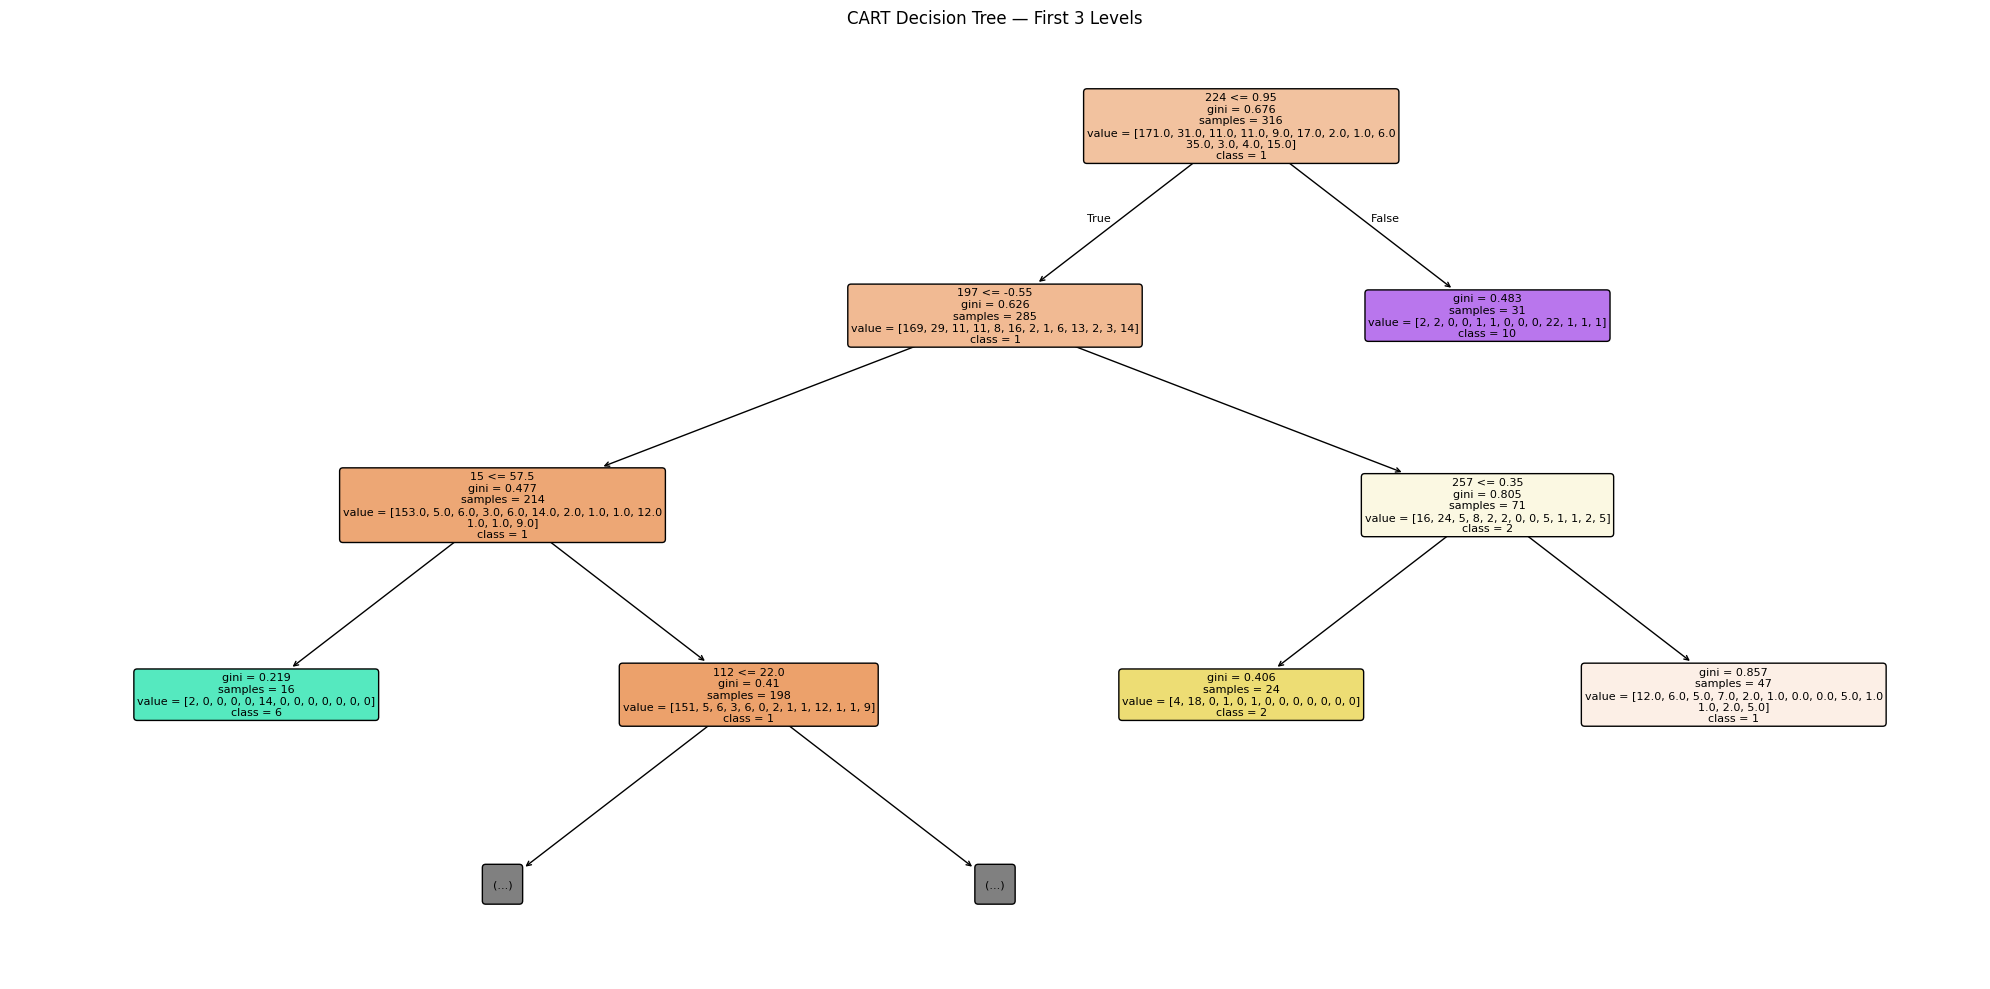

In [17]:
cm_cart = confusion_matrix(y_test, pred_cart, labels=class_labels)
plt.figure(figsize=(10, 8))
ConfusionMatrixDisplay(cm_cart, display_labels=class_labels).plot(
    xticks_rotation=90, colorbar=False
)
plt.title("CART Confusion Matrix")
plt.tight_layout()
plt.show()

cart_tree = cart_model.named_steps["model"]
kept_cart_features = X_train.columns[
    cart_model.named_steps["remove_constant"].get_support()
]

plt.figure(figsize=(20, 10))
plot_tree(
    cart_tree,
    feature_names=[str(c + 1) for c in kept_cart_features],
    class_names=[str(c) for c in cart_tree.classes_],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("CART Decision Tree — First 3 Levels")
plt.tight_layout()
plt.show()

## A2. Support Vector Machine (SVM)

In [18]:
svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold(threshold=0.0)),
    ("scale", StandardScaler()),
    ("model", SVC(kernel="rbf", C=1.0, class_weight="balanced"))
])

svm_model.fit(X_train, y_train)
pred_svm = svm_model.predict(X_test)

print("SVM accuracy:", round(accuracy_score(y_test, pred_svm), 4))
print(classification_report(
    y_test, pred_svm, labels=class_labels, zero_division=0
))

SVM accuracy: 0.5588
              precision    recall  f1-score   support

           1       0.77      0.73      0.75        74
           2       0.26      0.77      0.38        13
           3       1.00      0.50      0.67         4
           4       0.80      1.00      0.89         4
           5       0.00      0.00      0.00         4
           6       0.12      0.12      0.12         8
           7       0.00      0.00      0.00         1
           8       0.00      0.00      0.00         1
           9       0.00      0.00      0.00         3
          10       0.71      0.33      0.45        15
          14       0.00      0.00      0.00         1
          15       0.00      0.00      0.00         1
          16       0.00      0.00      0.00         7

    accuracy                           0.56       136
   macro avg       0.28      0.27      0.25       136
weighted avg       0.58      0.56      0.55       136



## A3. Naive Bayes

In [19]:
nb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold(threshold=0.0)),
    ("model", GaussianNB())
])

nb_model.fit(X_train, y_train)
pred_nb = nb_model.predict(X_test)

print("Naive Bayes accuracy:", round(accuracy_score(y_test, pred_nb), 4))
print(classification_report(
    y_test, pred_nb, labels=class_labels, zero_division=0
))

Naive Bayes accuracy: 0.1471
              precision    recall  f1-score   support

           1       0.29      0.05      0.09        74
           2       0.25      0.15      0.19        13
           3       0.29      0.50      0.36         4
           4       0.11      0.50      0.18         4
           5       0.00      0.00      0.00         4
           6       0.09      0.62      0.16         8
           7       0.00      0.00      0.00         1
           8       0.00      0.00      0.00         1
           9       0.50      0.33      0.40         3
          10       0.36      0.27      0.31        15
          14       0.00      0.00      0.00         1
          15       0.00      0.00      0.00         1
          16       0.00      0.00      0.00         7

    accuracy                           0.15       136
   macro avg       0.15      0.19      0.13       136
weighted avg       0.25      0.15      0.14       136



# Part B — Extend the work with Random Forest

Random Forest is the additional model. It is not one of the models evaluated in the reference paper. It combines many decision trees, which can reduce the variance of a single tree.

Random Forest accuracy: 0.6618
              precision    recall  f1-score   support

           1       0.63      0.99      0.77        74
           2       0.86      0.46      0.60        13
           3       0.57      1.00      0.73         4
           4       1.00      0.50      0.67         4
           5       0.00      0.00      0.00         4
           6       1.00      0.12      0.22         8
           7       0.00      0.00      0.00         1
           8       0.00      0.00      0.00         1
           9       1.00      1.00      1.00         3
          10       1.00      0.07      0.12        15
          14       0.00      0.00      0.00         1
          15       0.00      0.00      0.00         1
          16       0.00      0.00      0.00         7

    accuracy                           0.66       136
   macro avg       0.47      0.32      0.32       136
weighted avg       0.66      0.66      0.57       136



<Figure size 1000x800 with 0 Axes>

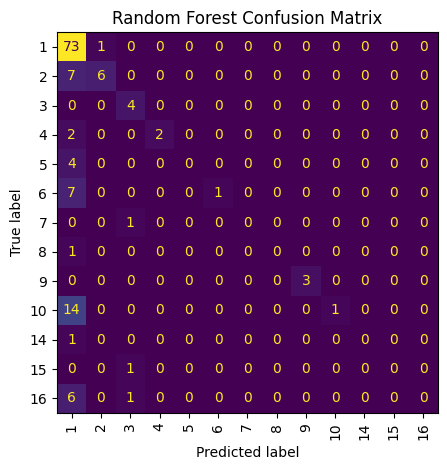

,Importance
14,0.040896
227,0.019091
241,0.017231
229,0.016596
148,0.016580
5,0.016048
2,0.015935
8,0.015684
6,0.014763
113,0.014642


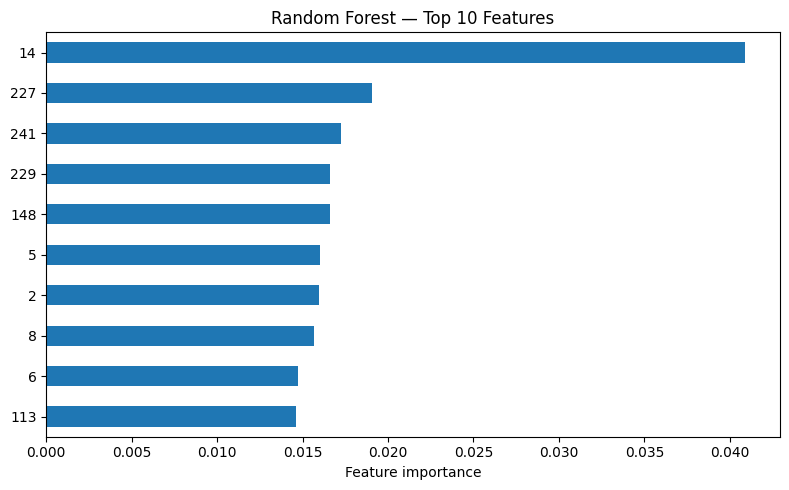

In [20]:
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold(threshold=0.0)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)

print("Random Forest accuracy:", round(accuracy_score(y_test, pred_rf), 4))
print(classification_report(
    y_test, pred_rf, labels=class_labels, zero_division=0
))

cm_rf = confusion_matrix(y_test, pred_rf, labels=class_labels)
plt.figure(figsize=(10, 8))
ConfusionMatrixDisplay(cm_rf, display_labels=class_labels).plot(
    xticks_rotation=90, colorbar=False
)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

forest = rf_model.named_steps["model"]
kept_rf_features = X_train.columns[
    rf_model.named_steps["remove_constant"].get_support()
]
importance = pd.Series(forest.feature_importances_, index=kept_rf_features)
importance = importance.sort_values(ascending=False).head(10)

display(importance.rename("Importance").to_frame())
importance.sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("Feature importance")
plt.title("Random Forest — Top 10 Features")
plt.tight_layout()
plt.show()

# Part C — Compare models and reference results

All four models use the same train/test split. Accuracy, weighted precision/recall/F1 and macro F1 are reported. Weighted metrics reflect the common classes more strongly; macro F1 gives each class equal weight and helps expose poor performance on rare classes.

In [21]:
predictions = {
    "CART": pred_cart,
    "SVM": pred_svm,
    "Naive Bayes": pred_nb,
    "Random Forest": pred_rf
}

def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Weighted precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Weighted recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

metrics_by_model = {
    name: get_metrics(y_test, pred)
    for name, pred in predictions.items()
}

comparison = pd.DataFrame(metrics_by_model).T
display(comparison.round(4))
comparison.to_csv("results/model_comparison.csv")

,Accuracy,Weighted precision,Weighted recall,Weighted F1,Macro F1
CART,0.6324,0.5577,0.6324,0.5890,0.2367
SVM,0.5588,0.5833,0.5588,0.5481,0.2515
Naive Bayes,0.1471,0.2474,0.1471,0.1357,0.1301
Random Forest,0.6618,0.6647,0.6618,0.5676,0.3164


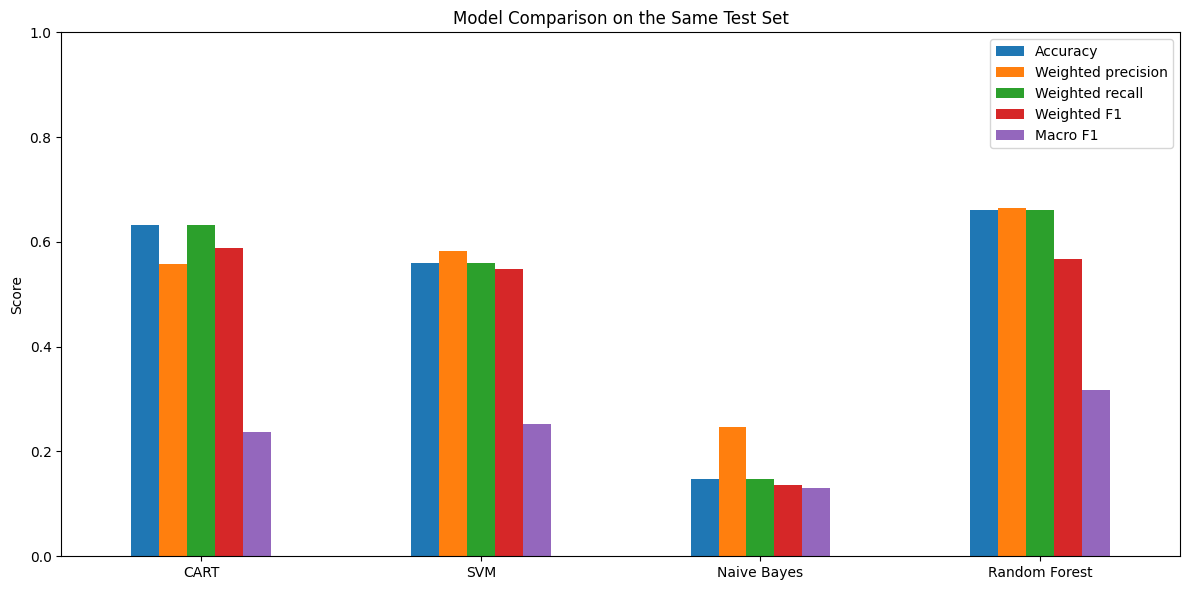

,Model,Reference paper accuracy,Our CART test accuracy,Interpretation
0,CART,Approximately 80% (reported),63.24%,Not a like-for-like comparison: exact split/se...


Highest test accuracy: Random Forest (66.18%)
Highest macro F1: Random Forest (31.64%)


In [22]:
metric_names = ["Accuracy", "Weighted precision", "Weighted recall", "Weighted F1", "Macro F1"]
comparison[metric_names].plot(kind="bar", figsize=(12, 6))
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Model Comparison on the Same Test Set")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

reference_table = pd.DataFrame([
    {
        "Model": "CART",
        "Reference paper accuracy": "Approximately 80% (reported)",
        "Our CART test accuracy": f"{metrics_by_model['CART']['Accuracy'] * 100:.2f}%",
        "Interpretation": "Not a like-for-like comparison: exact split/settings differ or are unspecified"
    }
])
display(reference_table)
reference_table.to_csv("results/reference_vs_our_cart.csv", index=False)

best_accuracy = comparison["Accuracy"].idxmax()
best_macro_f1 = comparison["Macro F1"].idxmax()
print(f"Highest test accuracy: {best_accuracy} ({comparison.loc[best_accuracy, 'Accuracy']:.2%})")
print(f"Highest macro F1: {best_macro_f1} ({comparison.loc[best_macro_f1, 'Macro F1']:.2%})")

## C1. Ten-fold cross-validation

In [23]:
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
models = [
    ("CART", cart_model),
    ("SVM", svm_model),
    ("Naive Bayes", nb_model),
    ("Random Forest", rf_model)
]

cv_rows = []
for name, model in models:
    scores = cross_validate(
        model, X, y, cv=cv, scoring="accuracy",
        return_train_score=False, n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "Mean 10-fold accuracy": scores["test_score"].mean(),
        "Standard deviation": scores["test_score"].std()
    })

cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))
cv_results.to_csv("results/ten_fold_cross_validation.csv", index=False)


,Model,Mean 10-fold accuracy,Standard deviation
0,CART,0.6659,0.0867
1,SVM,0.5776,0.0619
2,Naive Bayes,0.1394,0.0372
3,Random Forest,0.6838,0.0692


## Conclusion

Use the comparison table to identify the strongest model on this particular test split. Do not choose based on accuracy alone: this dataset is imbalanced, so also consider macro F1 and the per-class classification report. Random Forest is the extension model; it can reduce the variance of a single decision tree, but it is not guaranteed to perform better on this small dataset.

**Limitations:** this is not an exact replication of the reference paper because the paper's full split and software settings are not specified. Some classes have very few examples, making scores unstable. The dataset's coded measurements are treated as numeric. This model is for coursework only and must not be used for clinical decisions.